# Week 4 Assignment — Neural Network Classifier on the Pothole Dataset

**Dataset:** *Pothole and Plain Road Images* (Kaggle, `virenbr11/pothole-and-plain-rode-images`) —
a genuine two-class dataset that pairs the Week 2 pothole images with clean/plain road images,
so we can build a true **whole-image** binary classifier (pothole vs. no pothole).

**Task:** Implement a neural network classifier on this dataset, tune hyperparameters and observe
the effect on training/validation curves, and evaluate the final model with a **confusion matrix,
precision, recall and F1-score**.

## Assignment requirements

This notebook implements a neural network classifier on the chosen dataset (or its closest
viable substitute, see the note below), adjusts its hyperparameters — learning rate, batch size,
dropout, and optimizer — across six configurations while observing the resulting training and
validation loss/accuracy curves, and evaluates the final model's performance on a held-out test
split using a confusion matrix, precision, recall, and F1-score. The accompanying `REPORT.md`
documents the discoveries from this experimentation phase, with snapshots of every plot produced
below (class balance, sample images, hyperparameter comparison, training curves, confusion
matrix) embedded alongside the corresponding code to visually clarify both the process and the
results.


**Note on dataset choice.** The original Week 2 dataset (`Pothole.v1-raw.yolov8`, a YOLOv8
object-detection export) turned out to contain **no** pothole-free images at all — every image has
at least one annotated pothole box. That made a genuine whole-image "pothole present / absent"
classifier impossible on that dataset alone. This Kaggle dataset supplies the missing negative
("Plain" = clean road) class, giving a proper two-class classification problem:

| Folder | Class | Meaning |
|---|---|---|
| `Plain`   | 0 | clean road, no pothole |
| `Pothole` | 1 | road with a pothole |

Raw folders shipped with the dataset:

| Folder | Plain (0) | Pothole (1) | Total |
|---|---|---|---|
| train | 367 | 357 | 724 |
| test        | 8   | 8   | 16  |

The dataset's own `test` folder only has 16 images, which is too small to draw reliable
conclusions from (each image is worth >6 percentage points of accuracy). Instead, **all 740
images (train + test) are pooled and re-split** into a single stratified 70% / 15% / 15%
train / validation / test partition, giving a test set of roughly 111 images instead of 16.
Hyperparameter tuning only ever sees the train/validation portions; the re-carved test split is
held out until the final evaluation in Section 6.

In [1]:
import os, glob, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                              f1_score, accuracy_score, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

DATA_ROOT = os.path.join('..', 'My Dataset')
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)
IMG_SIZE = 128


Using device: cpu


## 1. Build the image index and a larger, re-carved train / validation / test split

In [2]:
def list_images(folder, label):
    exts = ('*.jpg', '*.jpeg', '*.png')
    paths = []
    for ext in exts:
        paths.extend(glob.glob(os.path.join(folder, ext)))
    return pd.DataFrame({'image': sorted(paths), 'label': label})

all_df = pd.concat([
    list_images(os.path.join(DATA_ROOT, 'train', 'Plain'), 0),
    list_images(os.path.join(DATA_ROOT, 'train', 'Pothole'), 1),
    list_images(os.path.join(DATA_ROOT, 'test', 'Plain'), 0),
    list_images(os.path.join(DATA_ROOT, 'test', 'Pothole'), 1),
], ignore_index=True).drop_duplicates(subset='image').reset_index(drop=True)

print('pooled total:', len(all_df), '| pothole:', int(all_df.label.sum()),
      '| plain:', int((all_df.label==0).sum()))

# Stratified 70% / 15% / 15% train / validation / test split over the full pool.
train_df, holdout_df = train_test_split(
    all_df, test_size=0.30, stratify=all_df['label'], random_state=SEED)
valid_df, test_df = train_test_split(
    holdout_df, test_size=0.50, stratify=holdout_df['label'], random_state=SEED)

print('train:', len(train_df), 'valid:', len(valid_df), 'test:', len(test_df))
summary = pd.DataFrame({
    'split': ['train', 'valid', 'test'],
    'total': [len(train_df), len(valid_df), len(test_df)],
    'pothole (1)': [train_df.label.sum(), valid_df.label.sum(), test_df.label.sum()],
    'plain (0)': [(train_df.label==0).sum(), (valid_df.label==0).sum(), (test_df.label==0).sum()],
})
summary


pooled total: 739 | pothole: 365 | plain: 374
train: 517 valid: 111 test: 111


,split,total,pothole (1),plain (0)
0,train,517,255,262
1,valid,111,55,56
2,test,111,55,56


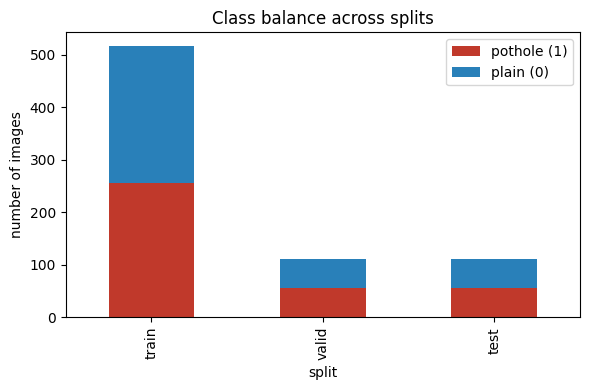

In [3]:
fig, ax = plt.subplots(figsize=(6,4))
summary.set_index('split')[['pothole (1)', 'plain (0)']].plot(
    kind='bar', stacked=True, ax=ax, color=['#c0392b', '#2980b9'])
ax.set_ylabel('number of images')
ax.set_title('Class balance across splits')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '01_class_balance.png'), dpi=150)
plt.show()


## 2. Look at a few samples (snapshot of the data)

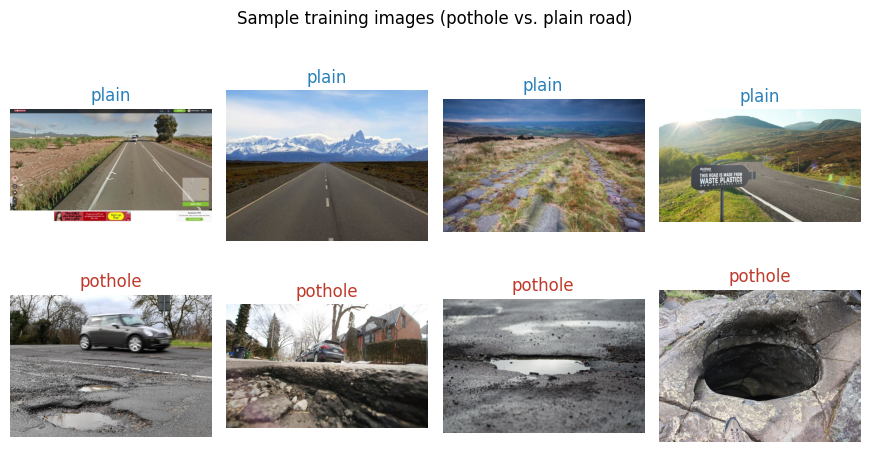

In [4]:
def show_samples(df, n=8, title='samples'):
    sample = pd.concat([
        df[df['label'] == 0].sample(n=n // 2, random_state=SEED),
        df[df['label'] == 1].sample(n=n // 2, random_state=SEED),
    ], ignore_index=True)
    fig, axes = plt.subplots(2, n // 2, figsize=(2.2 * (n // 2), 5))
    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        im = Image.open(row['image']).convert('RGB')
        ax.imshow(im)
        ax.set_title('pothole' if row['label'] == 1 else 'plain',
                      color='#c0392b' if row['label'] == 1 else '#2980b9')
        ax.axis('off')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, '02_sample_images.png'), dpi=150)
    plt.show()

show_samples(train_df, n=8, title='Sample training images (pothole vs. plain road)')


## 3. Dataset / DataLoader

Images are cached as resized tensors the first time they are read, so re-running several
hyperparameter configurations does not repeatedly decode JPEGs from disk.

In [5]:
class PotholeDataset(Dataset):
    def __init__(self, df, img_size=IMG_SIZE, augment=False):
        self.paths = df['image'].tolist()
        self.labels = df['label'].astype(np.float32).tolist()
        self.img_size = img_size
        self.augment = augment
        self._cache = [None] * len(self.paths)

    def __len__(self):
        return len(self.paths)

    def _load(self, idx):
        if self._cache[idx] is None:
            im = Image.open(self.paths[idx]).convert('RGB').resize((self.img_size, self.img_size))
            self._cache[idx] = np.asarray(im, dtype=np.float32) / 255.0
        return self._cache[idx].copy()

    def __getitem__(self, idx):
        arr = self._load(idx)
        if self.augment and random.random() < 0.5:
            arr = arr[:, ::-1, :].copy()  # horizontal flip
        tensor = torch.from_numpy(arr).permute(2, 0, 1)  # CHW
        label = torch.tensor(self.labels[idx])
        return tensor, label

train_ds = PotholeDataset(train_df, augment=True)
valid_ds = PotholeDataset(valid_df, augment=False)
test_ds  = PotholeDataset(test_df,  augment=False)
len(train_ds), len(valid_ds), len(test_ds)


(517, 111, 111)

## 4. Neural network architecture (CNN)

In [6]:
class PotholeCNN(nn.Module):
    def __init__(self, dropout=0.3, base_channels=16):
        super().__init__()
        c = base_channels
        self.features = nn.Sequential(
            nn.Conv2d(3, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(), nn.MaxPool2d(2),      # 128->64
            nn.Conv2d(c, c*2, 3, padding=1), nn.BatchNorm2d(c*2), nn.ReLU(), nn.MaxPool2d(2),  # 64->32
            nn.Conv2d(c*2, c*4, 3, padding=1), nn.BatchNorm2d(c*4), nn.ReLU(), nn.MaxPool2d(2),# 32->16
            nn.Conv2d(c*4, c*8, 3, padding=1), nn.BatchNorm2d(c*8), nn.ReLU(), nn.MaxPool2d(2),# 16->8
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(c*8, 64), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x).squeeze(1)

PotholeCNN()


PotholeCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
 

## 5. Hyperparameter tuning

We train the same architecture under several hyperparameter configurations and compare
validation performance, varying:

- **learning rate**
- **batch size**
- **dropout**
- **optimizer** (Adam vs SGD+momentum)


In [7]:
def run_experiment(name, lr=1e-3, batch_size=32, dropout=0.3, optimizer_name='adam',
                    epochs=20, base_channels=16, weight_decay=0.0):
    torch.manual_seed(SEED)
    model = PotholeCNN(dropout=dropout, base_channels=base_channels).to(DEVICE)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_ds, batch_size=64, shuffle=False)

    if optimizer_name == 'adam':
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    criterion = nn.BCEWithLogitsLoss()

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    t0 = time.time()
    for epoch in range(epochs):
        model.train()
        tl, tc, tn = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            opt.step()
            tl += loss.item() * xb.size(0)
            tc += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
            tn += xb.size(0)

        model.eval()
        vl, vc, vn = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                loss = criterion(logits, yb)
                vl += loss.item() * xb.size(0)
                vc += ((torch.sigmoid(logits) > 0.5).float() == yb).sum().item()
                vn += xb.size(0)

        history['train_loss'].append(tl/tn); history['train_acc'].append(tc/tn)
        history['val_loss'].append(vl/vn); history['val_acc'].append(vc/vn)

    elapsed = time.time() - t0
    print(f"[{name}] done in {elapsed:.1f}s | final val_acc={history['val_acc'][-1]:.3f} "
          f"best val_acc={max(history['val_acc']):.3f}")
    return model, history

configs = [
    dict(name='A_baseline',        lr=1e-3, batch_size=32, dropout=0.3, optimizer_name='adam', epochs=20),
    dict(name='B_low_lr',          lr=1e-4, batch_size=32, dropout=0.3, optimizer_name='adam', epochs=20),
    dict(name='C_high_lr',         lr=5e-3, batch_size=32, dropout=0.3, optimizer_name='adam', epochs=20),
    dict(name='D_small_batch',     lr=1e-3, batch_size=8,  dropout=0.3, optimizer_name='adam', epochs=20),
    dict(name='E_more_dropout',    lr=1e-3, batch_size=32, dropout=0.6, optimizer_name='adam', epochs=20),
    dict(name='F_sgd_momentum',    lr=1e-2, batch_size=32, dropout=0.3, optimizer_name='sgd',  epochs=20),
]

results = {}
for cfg in configs:
    model, history = run_experiment(**cfg)
    results[cfg['name']] = {'model': model, 'history': history, 'config': cfg}


C:\Users\devko\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


[A_baseline] done in 129.0s | final val_acc=0.748 best val_acc=0.955


[B_low_lr] done in 95.8s | final val_acc=0.946 best val_acc=0.973


[C_high_lr] done in 92.3s | final val_acc=0.802 best val_acc=0.928


[D_small_batch] done in 86.8s | final val_acc=0.910 best val_acc=0.946


[E_more_dropout] done in 108.1s | final val_acc=0.694 best val_acc=0.973


[F_sgd_momentum] done in 110.0s | final val_acc=0.793 best val_acc=0.919


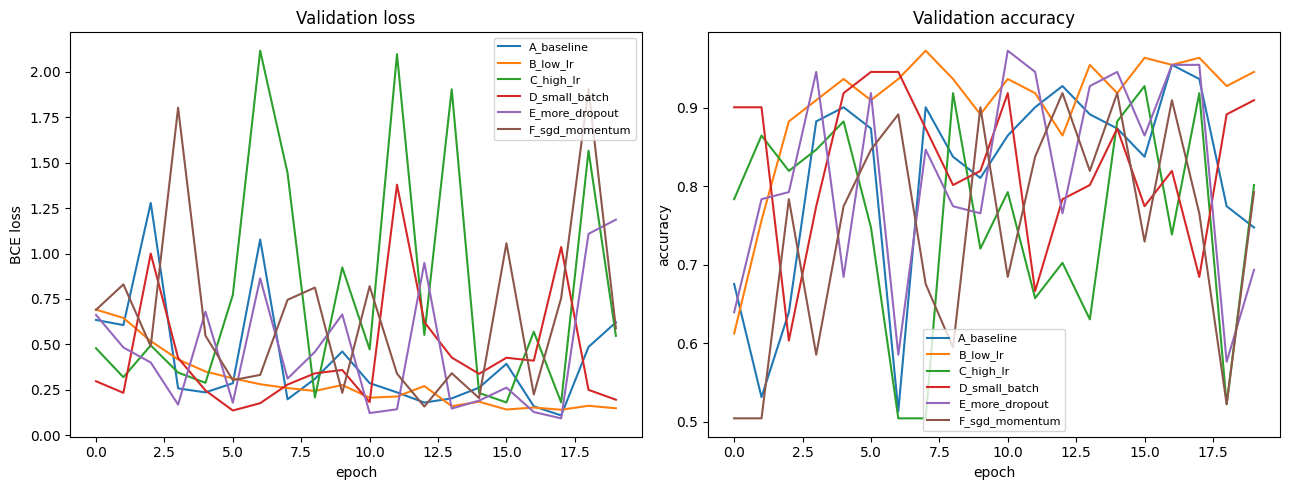

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
for name, r in results.items():
    axes[0].plot(r['history']['val_loss'], label=name)
    axes[1].plot(r['history']['val_acc'], label=name)
axes[0].set_title('Validation loss'); axes[0].set_xlabel('epoch'); axes[0].set_ylabel('BCE loss')
axes[1].set_title('Validation accuracy'); axes[1].set_xlabel('epoch'); axes[1].set_ylabel('accuracy')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '03_hyperparam_val_curves.png'), dpi=150)
plt.show()


In [9]:
compare_rows = []
for name, r in results.items():
    h = r['history']
    compare_rows.append({
        'config': name,
        **{k: v for k, v in r['config'].items() if k != 'name'},
        'final_train_acc': h['train_acc'][-1],
        'final_val_acc': h['val_acc'][-1],
        'best_val_acc': max(h['val_acc']),
        'final_val_loss': h['val_loss'][-1],
    })
compare_df = pd.DataFrame(compare_rows).sort_values('best_val_acc', ascending=False)
compare_df


,config,lr,batch_size,dropout,optimizer_name,epochs,final_train_acc,final_val_acc,best_val_acc,final_val_loss
1,B_low_lr,0.0001,32,0.3,adam,20,0.924565,0.945946,0.972973,0.147582
4,E_more_dropout,0.0010,32,0.6,adam,20,0.891683,0.693694,0.972973,1.186605
0,A_baseline,0.0010,32,0.3,adam,20,0.924565,0.747748,0.954955,0.620804
3,D_small_batch,0.0010,8,0.3,adam,20,0.930368,0.909910,0.945946,0.194863
2,C_high_lr,0.0050,32,0.3,adam,20,0.909091,0.801802,0.927928,0.546670
5,F_sgd_momentum,0.0100,32,0.3,sgd,20,0.885880,0.792793,0.918919,0.588036


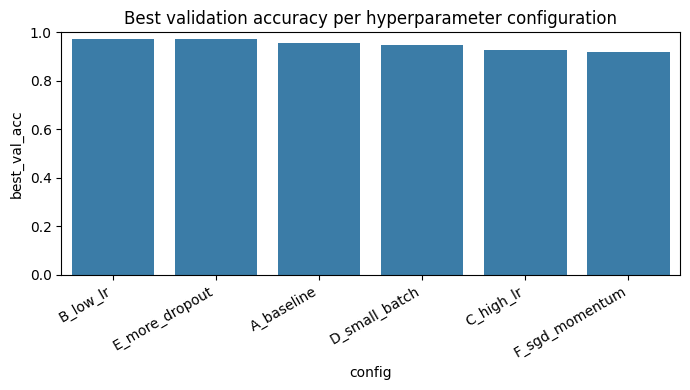

Best configuration: B_low_lr


In [10]:
fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(data=compare_df, x='config', y='best_val_acc', ax=ax, color='#2980b9')
ax.set_ylim(0, 1)
ax.set_title('Best validation accuracy per hyperparameter configuration')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '04_hyperparam_comparison.png'), dpi=150)
plt.show()

best_name = compare_df.iloc[0]['config']
print('Best configuration:', best_name)
best_model = results[best_name]['model']
best_history = results[best_name]['history']


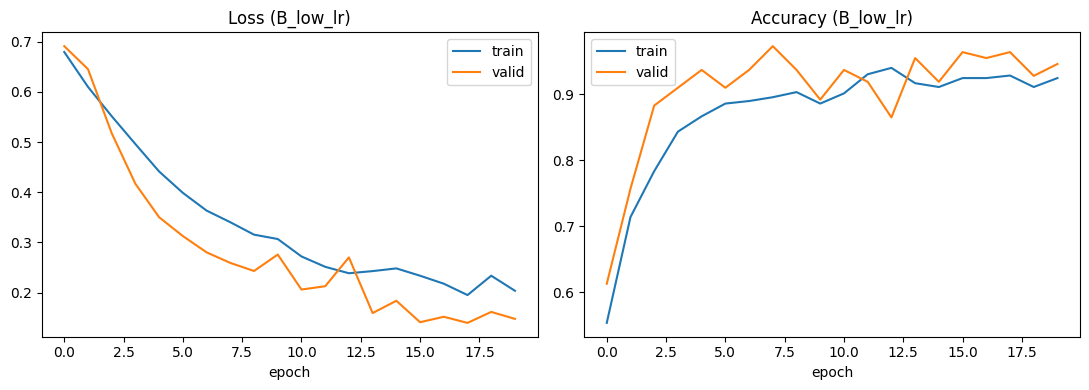

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].plot(best_history['train_loss'], label='train')
axes[0].plot(best_history['val_loss'], label='valid')
axes[0].set_title(f'Loss ({best_name})'); axes[0].set_xlabel('epoch'); axes[0].legend()
axes[1].plot(best_history['train_acc'], label='train')
axes[1].plot(best_history['val_acc'], label='valid')
axes[1].set_title(f'Accuracy ({best_name})'); axes[1].set_xlabel('epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '05_best_model_curves.png'), dpi=150)
plt.show()


## 6. Evaluation on the held-out **test** split

We now evaluate the best model (chosen by validation accuracy) on the re-carved, larger test
split (~15% of the full pooled dataset, ~111 images), using a **confusion matrix, precision,
recall and F1-score**.

In [12]:
def evaluate(model, ds):
    loader = DataLoader(ds, batch_size=64, shuffle=False)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            logits = model(xb)
            preds = (torch.sigmoid(logits) > 0.5).float().cpu().numpy()
            all_preds.extend(preds.tolist())
            all_labels.extend(yb.numpy().tolist())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = evaluate(best_model, test_ds)

acc  = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec  = recall_score(y_true, y_pred, zero_division=0)
f1   = f1_score(y_true, y_pred, zero_division=0)

print(f'Test accuracy : {acc:.3f}')
print(f'Precision     : {prec:.3f}')
print(f'Recall        : {rec:.3f}')
print(f'F1-score      : {f1:.3f}')
print()
print(classification_report(y_true, y_pred, labels=[0, 1],
                             target_names=['plain', 'pothole'], zero_division=0))


Test accuracy : 0.964
Precision     : 0.964
Recall        : 0.964
F1-score      : 0.964

              precision    recall  f1-score   support

       plain       0.96      0.96      0.96        56
     pothole       0.96      0.96      0.96        55

    accuracy                           0.96       111
   macro avg       0.96      0.96      0.96       111
weighted avg       0.96      0.96      0.96       111



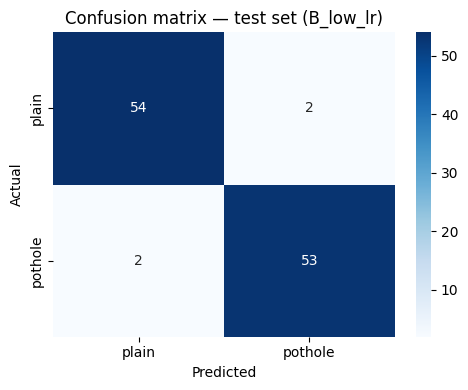

In [13]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['plain', 'pothole'], yticklabels=['plain', 'pothole'], ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'Confusion matrix — test set ({best_name})')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, '06_confusion_matrix.png'), dpi=150)
plt.show()


In [14]:
metrics_summary = {
    'best_config': best_name,
    'test_accuracy': float(acc),
    'test_precision': float(prec),
    'test_recall': float(rec),
    'test_f1': float(f1),
    'confusion_matrix': cm.tolist(),
    'hyperparameter_comparison': compare_df.to_dict(orient='records'),
}
with open(os.path.join(OUT_DIR, 'metrics_summary.json'), 'w') as f:
    json.dump(metrics_summary, f, indent=2)
metrics_summary


{'best_config': 'B_low_lr',
 'test_accuracy': 0.963963963963964,
 'test_precision': 0.9636363636363636,
 'test_recall': 0.9636363636363636,
 'test_f1': 0.9636363636363636,
 'confusion_matrix': [[54, 2], [2, 53]],
 'hyperparameter_comparison': [{'config': 'B_low_lr',
   'lr': 0.0001,
   'batch_size': 32,
   'dropout': 0.3,
   'optimizer_name': 'adam',
   'epochs': 20,
   'final_train_acc': 0.9245647969052224,
   'final_val_acc': 0.9459459459459459,
   'best_val_acc': 0.972972972972973,
   'final_val_loss': 0.1475819154634132},
  {'config': 'E_more_dropout',
   'lr': 0.001,
   'batch_size': 32,
   'dropout': 0.6,
   'optimizer_name': 'adam',
   'epochs': 20,
   'final_train_acc': 0.8916827852998066,
   'final_val_acc': 0.6936936936936937,
   'best_val_acc': 0.972972972972973,
   'final_val_loss': 1.1866045019648097},
  {'config': 'A_baseline',
   'lr': 0.001,
   'batch_size': 32,
   'dropout': 0.3,
   'optimizer_name': 'adam',
   'epochs': 20,
   'final_train_acc': 0.9245647969052224,
  

## 7. Discussion

- Unlike the raw Week 2 YOLOv8 detection export (which has no pothole-free images), this Kaggle
  dataset supplies genuine `Plain` (clean road) and `Pothole` classes, enabling a true whole-image
  binary classifier instead of a patch-cropping workaround.
- The dataset's own `train`/`test` folders were pooled and re-split 70/15/15 (stratified) to grow
  the test set from the shipped 16 images to roughly 111 images, giving a far less noisy final
  evaluation while keeping test data fully held out from training and hyperparameter selection.
- A compact 4-block CNN (16→32→64→128 channels) with batch-norm, dropout and global average
  pooling was trained on 128×128 RGB images.
- Six hyperparameter configurations were compared (learning rate, batch size, dropout,
  optimizer); see the comparison table/plot above for which configuration generalised best to
  the validation split.
- The confusion matrix and precision/recall/F1 on the untouched, re-carved test split are
  reported above; see `outputs/metrics_summary.json` for the exact numbers reproduced in the
  accompanying report.
